# Revisão de código

Olá!

Meu nome é Suelen. Estou feliz em revisar seu projeto hoje!

Quando vejo um erro pela primeira vez, apenas aponto. Deixarei você encontrá-lo e corrigi-lo sozinho. Além disso, ao longo do texto, farei algumas observações sobre melhorias no código e também farei comentários sobre suas percepções sobre o assunto. Mas se você ainda não consegue lidar com essa tarefa, darei uma dica mais precisa na próxima iteração e também alguns exemplos práticos. Estarei aberta a feedbacks e discussões sobre o tema.

Você pode encontrar meus comentários em caixas verdes, amarelas ou vermelhas como estas:


<div class="alert alert-block alert-success">
<b>Comentário: </b> <a class="tocSkip"></a>

Sucesso. Tudo está correto.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário: </b> <a class="tocSkip"></a>

Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">

<b>Comentário: </b> <a class="tocSkip"></a>

O bloco requer algumas correções. O trabalho não pode ser aceito com os comentários vermelhos.
</div>

Você pode me responder usando isto:

<div class="alert alert-block alert-info">
<b>Resposta do aluno</b> <a class="tocSkip"></a>
</div>



<div class="alert alert-block alert-success">
<b>Comentário geral: </b> <a class="tocSkip"></a>

Parabéns pela conclusão do projeto, Andressa!👏🚀 TODAS as tarefas foram realizadas corretamente!

Espero que se sinta orgulhosa do seu projeto!


O projeto está aprovado! Continue com o excelente trabalho!

</div>

name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         9125
rating             6766
global_sales          0
dtype: int64
-------------------------------------------------
2
0
                           name platform  year_of_release         genre  \
0                    Wii Sports      Wii             2006        Sports   
1             Super Mario Bros.      NES             1985      Platform   
2                Mario Kart Wii      Wii             2008        Racing   
3             Wii Sports Resort      Wii             2009        Sports   
4      Pokemon Red/Pokemon Blue       GB             1996  Role-Playing   
5                        Tetris       GB             1989        Puzzle   
6         New Super Mario Bros.       DS             2006      Platform   
7                      Wii Play      Wii     

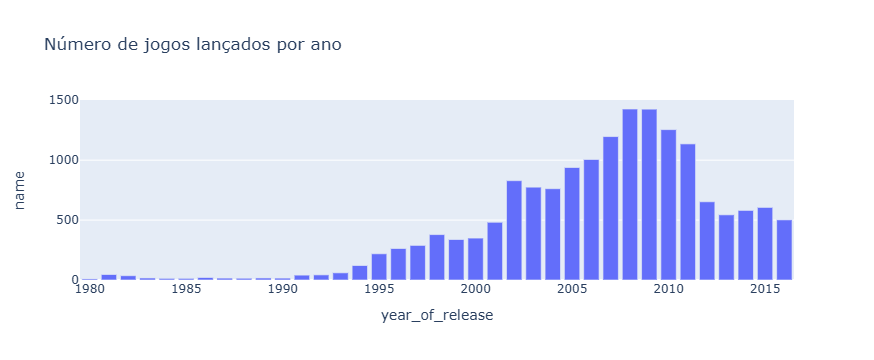

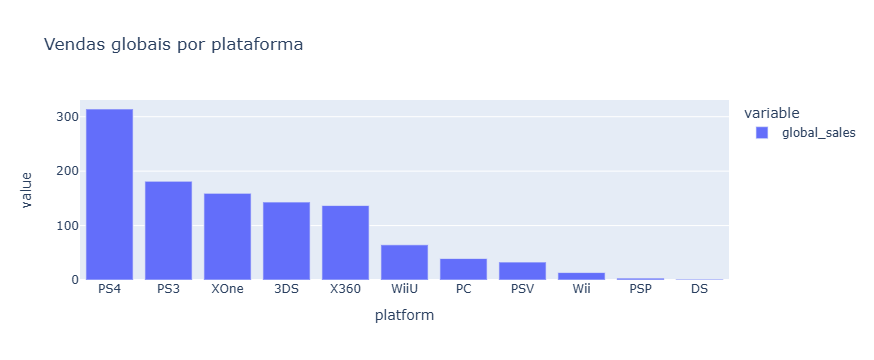

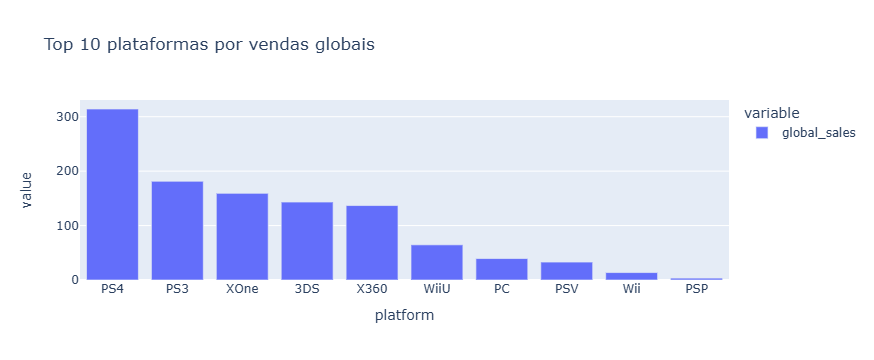

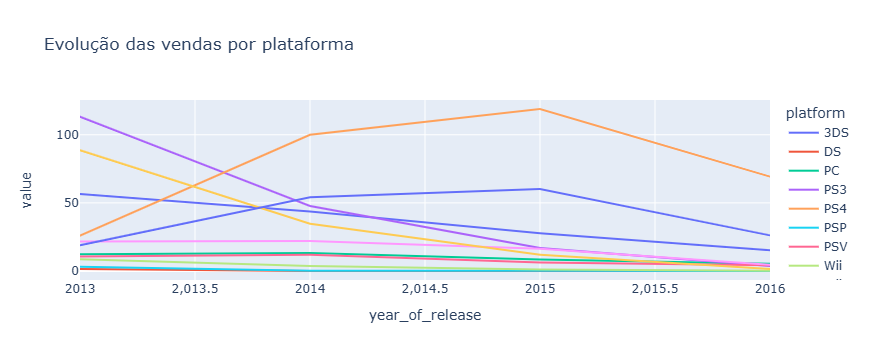

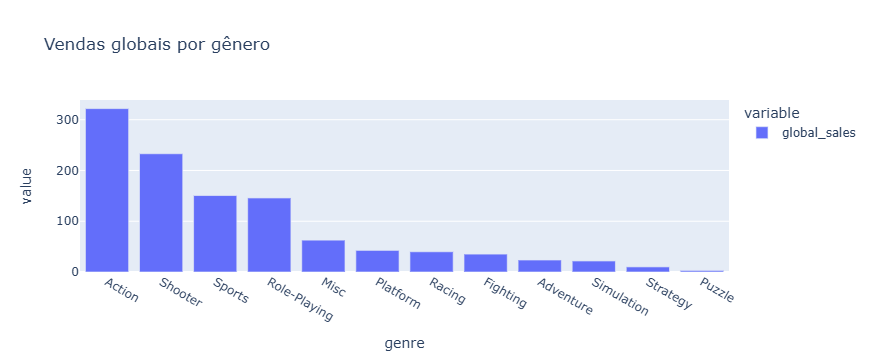

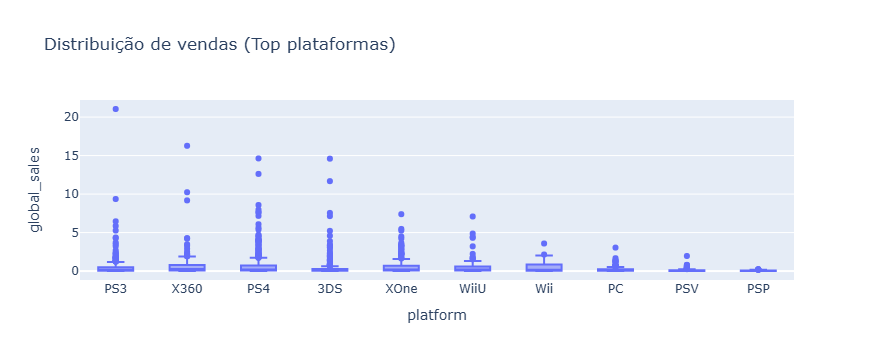

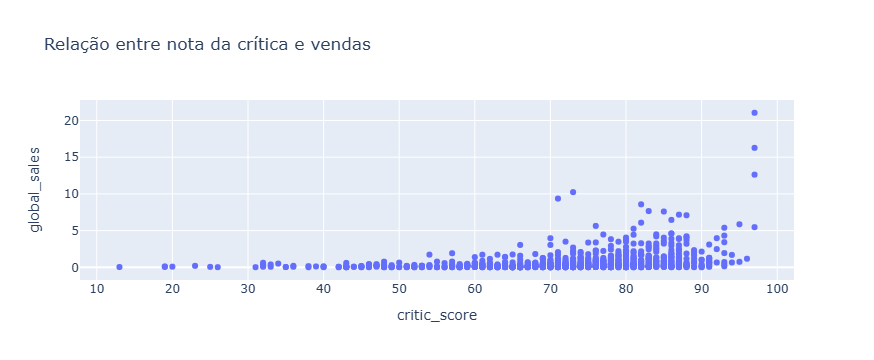

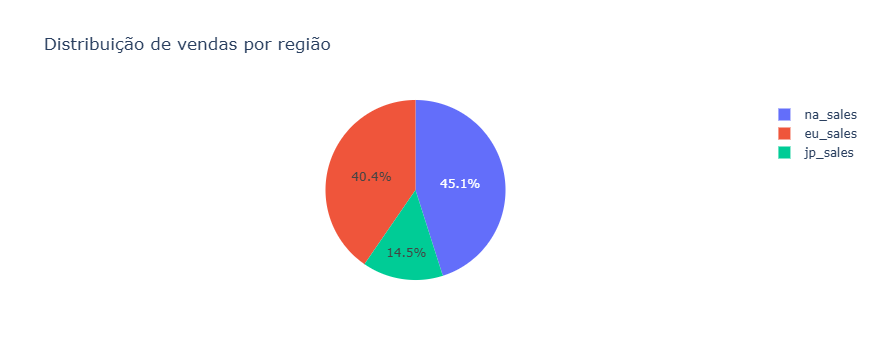

Plataforma por região
NA:
 platform
PS4     108.74
XOne     93.12
X360     81.66
PS3      63.50
3DS      38.20
Name: na_sales, dtype: float64
EU:
 platform
PS4     141.09
PS3      67.81
XOne     51.59
X360     42.52
3DS      30.96
Name: eu_sales, dtype: float64
JP:
 platform
3DS     67.81
PS3     23.35
PSV     18.59
PS4     15.96
WiiU    10.88
Name: jp_sales, dtype: float64


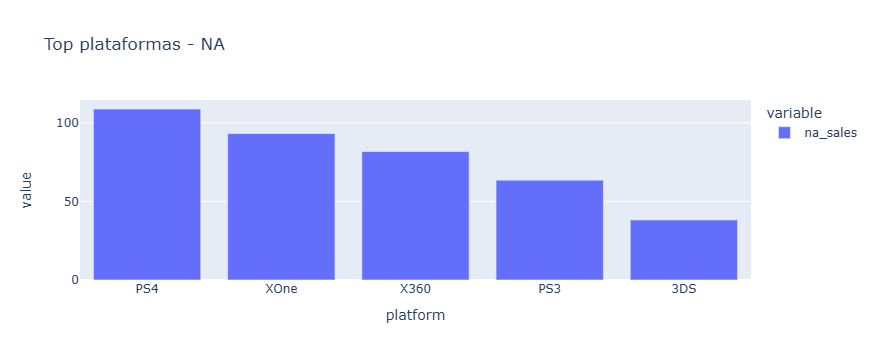

Gênero por região
NA:
 genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Name: na_sales, dtype: float64
EU:
 genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Name: eu_sales, dtype: float64
JP:
 genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Name: jp_sales, dtype: float64
classificação ESRB
NA:
 rating
M       165.21
E        79.05
E10+     54.24
T        49.79
Name: na_sales, dtype: float64
EU:
 rating
M       145.32
E        83.36
E10+     42.69
T        41.95
Name: eu_sales, dtype: float64
JP:
 rating
T       20.59
E       15.14
M       14.11
E10+     5.89
Name: jp_sales, dtype: float64


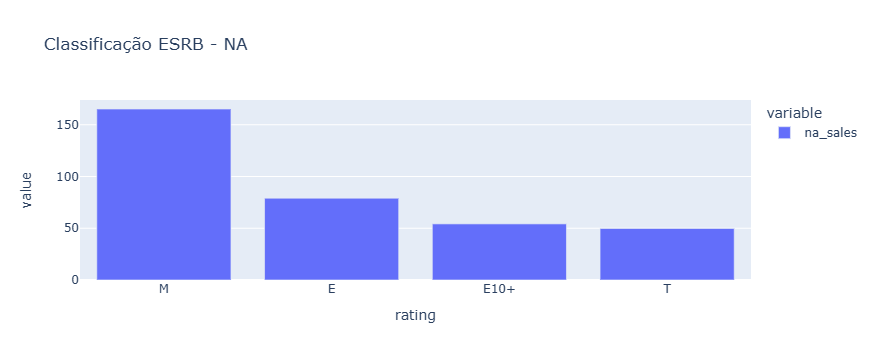

platform
PS4     28.228026
XOne    24.173200
X360    21.198276
PS3     16.484087
3DS      9.916411
Name: na_sales, dtype: float64
-----------------------------------------
Teste de hipotese Xbox One e PC
Média XOne: 6.521428571428572
Média PC: 6.2696774193548395
p-value: 0.14759594013430463
Não rejeitamos H0
----------------------------------------
Teste de hipotese Action vs Sports
Média Action: 6.837532133676092
Média Sports: 5.238124999999999
p-value: 1.4460039700704315e-20
Rejeitamos H0


In [14]:


# importar as bibliotecas necessárias
from scipy import stats  # testes estatísticos
import pandas as pd   # manipulação de dados
import plotly.express as px   # visualização de dados
import numpy as np  # operações numéricas

# carregar o dataset
df = pd.read_csv('/datasets/games.csv')  

# padronizar nomes das colunas 
df.columns = df.columns.str.lower()

# converter ano para inteiro com suporte a NaN
df['year_of_release'] = df['year_of_release'].astype('Int64')
# converter user_score (tem valores 'TBD')
df['user_score'] = df['user_score'].replace(['TBD', 'tbd'], np.nan) # faz o tratamento de dados sujos na coluna user_score.
df['user_score'] = pd.to_numeric(df['user_score'], errors='coerce') # converter user_score para numérico (tratando 'TBD' como ausente)
# cria a nova coluna para analise total de vendas global
df['global_sales'] = (
    df['na_sales'] +
    df['eu_sales'] + 
    df['jp_sales'] +
    df['other_sales']
)
# verificar valores ausentes
print(df.isna().sum())
print('-------------------------------------------------')
# verificar duplicados (geral e por chaves principais)
print(df.duplicated(subset=['name', 'platform', 'year_of_release']).sum())
print(df.duplicated().sum())

# remover duplicados (se houver)
df = df.drop_duplicates()

# visão geral dos dados
print(df.head(15)) # imprimir 
print('-------------------------------------------------')
df.info() # imprimir as informações do DataFrame
print('-------------------------------------------------')
print(df.describe(include='all')) # imprime a média, mediana, desvio padrão, mínimo e máximo (para colunas numéricas) e colunas categóricas. 
# -----------------------------
# ANÁLISE EXPLORATÓRIA 
# -----------------------------

# número de jogos lançados por ano
games_per_year = df.groupby('year_of_release')['name'].count().reset_index()
# filtrar dados recentes (evita distorções históricas)
df_recent = df[df['year_of_release'] >= 2013]

# grafico de jogos lançados por ano
fig = px.bar(
    games_per_year,
    x='year_of_release',
    y='name',
    title='Número de jogos lançados por ano'
)
fig.show()

# grafico de vendas globais por plataforma
platform_sales = df_recent.groupby('platform')['global_sales'].sum().sort_values(ascending=False)
fig = px.bar(
    platform_sales,
    title='Vendas globais por plataforma'
)

fig.show()

# gráfico top 10 plataformas 
top_platforms = platform_sales.head(10)

fig = px.bar(
    top_platforms,
    title='Top 10 plataformas por vendas globais'
)

fig.show()

# gráfico evolução das plataformas ao longo do tempo
platform_year = df_recent.pivot_table(
    index='year_of_release',
    columns='platform',
    values='global_sales',
    aggfunc='sum'
).fillna(0)

fig = px.line(
    platform_year,
    title='Evolução das vendas por plataforma'
)

fig.show()

# vendas por gênero
genre_sales = df_recent.groupby('genre')['global_sales'].sum().sort_values(ascending=False)

fig = px.bar(
    genre_sales,
    title='Vendas globais por gênero'
)

fig.show()

# distribuição de vendas (boxplot) para principais plataformas
top_platforms_list = platform_sales.head(10).index

fig = px.box(
    df_recent[df_recent['platform'].isin(top_platforms_list)],
    x='platform',
    y='global_sales',
    title='Distribuição de vendas (Top plataformas)'
)

fig.show()

# gráfico relação entre críticas e vendas
df_corr = df_recent.dropna(subset=['critic_score', 'global_sales'])

fig = px.scatter(
    df_corr,
    x='critic_score',
    y='global_sales',
    title='Relação entre nota da crítica e vendas'
)

fig.show()

# distribuição de vendas por região
region_sales = df_recent[['na_sales', 'eu_sales', 'jp_sales']].sum()

fig = px.pie(
    values=region_sales.values,
    names=region_sales.index,
    title='Distribuição de vendas por região'
)

fig.show()
# -----------------------------
# PERFIL POR REGIÃO
# -----------------------------
print('Plataforma por região')
# top plataformas por região
na_platforms = df_recent.groupby('platform')['na_sales'].sum().sort_values(ascending=False).head(5)
eu_platforms = df_recent.groupby('platform')['eu_sales'].sum().sort_values(ascending=False).head(5)
jp_platforms = df_recent.groupby('platform')['jp_sales'].sum().sort_values(ascending=False).head(5)

print("NA:\n", na_platforms)
print("EU:\n", eu_platforms)
print("JP:\n", jp_platforms)

# gráfico exemplo (NA)
fig = px.bar(na_platforms, title='Top plataformas - NA')
fig.show()

# top gêneros por região
print('Gênero por região')
na_genres = df_recent.groupby('genre')['na_sales'].sum().sort_values(ascending=False).head(5)
eu_genres = df_recent.groupby('genre')['eu_sales'].sum().sort_values(ascending=False).head(5)
jp_genres = df_recent.groupby('genre')['jp_sales'].sum().sort_values(ascending=False).head(5)

print("NA:\n", na_genres)
print("EU:\n", eu_genres)
print("JP:\n", jp_genres)

# classificação ESRB
print('classificação ESRB')
# impacto da classificação indicativa
na_rating = df_recent.groupby('rating')['na_sales'].sum().sort_values(ascending=False)
eu_rating = df_recent.groupby('rating')['eu_sales'].sum().sort_values(ascending=False)
jp_rating = df_recent.groupby('rating')['jp_sales'].sum().sort_values(ascending=False)

print("NA:\n", na_rating)
print("EU:\n", eu_rating)
print("JP:\n", jp_rating)

fig = px.bar(na_rating, title='Classificação ESRB - NA')
fig.show()
# cálculo de participação de mercado (exemplo NA)
na_share = (na_platforms / na_platforms.sum()) * 100
print(na_share)
print('-----------------------------------------')

# -----------------------------
# TESTE DE HIPÓTESES
# -----------------------------
print('Teste de hipotese Xbox One e PC')
alpha = 0.05 # nível de significância
df_test = df_recent.dropna(subset=['user_score']) # remover valores ausentes antes do teste
# separar amostras
xone = df_test[df_test['platform'] == 'XOne']['user_score'] 
pc = df_test[df_test['platform'] == 'PC']['user_score']

# estatísticas básicas
print("Média XOne:", xone.mean())
print("Média PC:", pc.mean())

# teste t de Welch (variâncias diferentes)
results = stats.ttest_ind(xone, pc, equal_var=False)

print("p-value:", results.pvalue)
# decisão
if results.pvalue < alpha:
    print("Rejeitamos H0") 
else:
    print("Não rejeitamos H0")

print('----------------------------------------')
# hipotese 2
print('Teste de hipotese Action vs Sports')
# separar amostras por gênero
action = df_test[df_test['genre'] == 'Action']['user_score']
sports = df_test[df_test['genre'] == 'Sports']['user_score']

print("Média Action:", action.mean())
print("Média Sports:", sports.mean())

# teste t
results = stats.ttest_ind(action, sports, equal_var=False)

print("p-value:", results.pvalue)

if results.pvalue < alpha:
    print("Rejeitamos H0")
else:
    print("Não rejeitamos H0")



<div class="alert alert-block alert-success">
<b>Comentário: </b> <a class="tocSkip"></a>

- EDA realizada corretamente! Bons gráficos

- Ambos os testes realizados corretamente!
- Boa escolha do p-valor.

- Sugestão: realizar teste de levene para validar a variancia das amostras antes do teste de hipótese. Saiba mais em: https://docs.scipy.org/doc//scipy-1.16.2/reference/generated/scipy.stats.levene.html

Etapa 2 

✔️ Tipos de dados

A coluna year_of_release foi convertida de float64 para Int64, pois representa anos inteiros. O tipo Int64 permite manter valores ausentes.

A coluna user_score foi convertida de object para float64, pois contém valores numéricos. Valores como 'TBD' foram substituídos por NaN antes da conversão.

✔️ Valores ausentes

Foram identificados valores ausentes em várias colunas, especialmente em critic_score, user_score e rating.

Esses valores podem estar ausentes porque:

- alguns jogos não receberam avaliações;
- dados antigos não foram registrados;
- certas informações não estavam disponíveis no momento da coleta.

Os valores 'TBD' na coluna user_score foram tratados como ausentes (NaN), pois indicam que a nota ainda não foi determinada.

Os valores ausentes não foram preenchidos para evitar distorções na análise.


Etapa 3

jogos lançados a cada ano:

- Crescimento ao longo do tempo
- Pico (geralmente entre 2005–2010)
- Queda recente (dados incompletos)

Insight

O número de lançamentos de jogos cresceu significativamente ao longo dos anos, atingindo um pico por volta de 2008–2009. Após esse período, há uma queda, possivelmente devido à incompletude dos dados mais recentes.

Variação de vendas
- Plataformas líderes (Wii, PS2, X360, etc.)
-Algumas plataformas dominam as vendas globais, com destaque para consoles populares, indicando forte preferência do mercado por determinados sistemas.

Plataformas:
- A análise das 10 principais plataformas mostra que poucas concentram a maior parte das vendas, indicando um mercado competitivo e concentrado.

Evolução das plataformas ao longo do tempo:
- As plataformas apresentam ciclos de vida bem definidos: crescimento, pico e declínio. Isso mostra a rápida evolução da indústria de jogos

Generos:
- Gêneros mais vendidos (Action, Sports, etc.)
- Gêneros como ação e esportes lideram as vendas globais, indicando maior preferência do público por experiências dinâmicas e competitivas.

Boxplot de vendas por plataforma:
- A distribuição de vendas é altamente desigual, com poucos jogos concentrando grande parte das vendas (outliers).

Relação entre críticas e vendas:
- Existe uma leve correlação positiva entre avaliações da crítica e vendas, mas não é determinante — jogos populares podem vender bem mesmo sem altas notas.

Vendas por região:
- Região dominante (geralmente América do Norte)
Diferença cultural (Japão costuma ser diferente)
- A América do Norte lidera as vendas globais, seguida pela Europa. O Japão apresenta um comportamento distinto, refletindo preferências regionais específicas.

Conclusão 

A análise exploratória mostrou que o mercado de jogos é altamente dinâmico, com ciclos claros de plataformas, concentração de vendas em poucos títulos e preferência por determinados gêneros. Além disso, há diferenças regionais significativas no comportamento do consumidor.

Etapa 4

Plataforma por regiao:
- As plataformas mais populares variam entre regiões. Na América do Norte e Europa, consoles como PlayStation e Xbox tendem a dominar, enquanto no Japão há maior preferência por plataformas portáteis e consoles locais. Isso evidencia diferenças culturais e de mercado.

Generos:
- Os gêneros mais populares também variam entre regiões. Enquanto ação e esportes são dominantes na América do Norte e Europa, o Japão apresenta maior preferência por RPGs, refletindo diferenças culturais no consumo de jogos.

Classificação:

- Classificações mais populares (E, T, M)
- As classificações ESRB influenciam as vendas, especialmente na América do Norte e Europa, onde jogos classificados como “E” (para todos) e “M” (maduros) apresentam maior volume de vendas. No Japão, essa influência é menos evidente, possivelmente devido a diferenças nos sistemas de classificação e preferências culturais.

Conclusão geral

A análise regional revelou diferenças significativas no comportamento dos usuários.
Enquanto América do Norte e Europa apresentam padrões semelhantes, com preferência por consoles como PlayStation e Xbox e gêneros como ação e esportes, o Japão se destaca com maior interesse por RPGs e plataformas da Nintendo.
Além disso, as classificações etárias impactam as vendas de forma mais evidente no mercado ocidental do que no japonês.
Esses resultados demonstram que fatores culturais e regionais desempenham papel fundamental no sucesso dos jogos.

Etapa 5 

- Foi adotado um nível de significância de 5% (α = 0,05), valor padrão em análises estatísticas. Esse nível representa um equilíbrio entre o risco de rejeitar incorretamente a hipótese nula (erro tipo I) e a sensibilidade do teste.
- Foi utilizado o teste t com variâncias desiguais (Welch’s t-test), pois não há garantia de que as variâncias das populações comparadas sejam iguais.
  
Hipotese 1:

- Foi realizado um teste t de Student para comparar as médias das avaliações dos usuários entre as plataformas Xbox One e PC. O p-value obtido foi 0,1476, que é maior que o nível de significância adotado (α = 0,05).

- Portanto, não rejeitamos a hipótese nula.

Não há evidência estatística suficiente para afirmar que as médias das avaliações dos usuários para Xbox One e PC são diferentes. Apesar de a média do Xbox One ser ligeiramente maior, essa diferença pode ser explicada por variação aleatória nos dados.
  
Hipotese 2:

- p-value: 1.44 × 10⁻²⁰ (extremamente pequeno)
- Foi realizado um teste t de Student para comparar as médias das avaliações dos usuários entre os gêneros Action e Sports.
- O p-value obtido foi extremamente baixo (≈ 0), muito menor que o nível de significância de 0,05.
- Portanto, rejeitamos a hipótese nula.

Há evidência estatística de que as médias das avaliações dos usuários para jogos de ação e esportes são diferentes.
Jogos de ação apresentam, em média, avaliações significativamente mais altas do que jogos de esportes.

Conclusão 

Os testes de hipóteses mostraram que nem todas as diferenças observadas nos dados são estatisticamente significativas.

Enquanto as avaliações entre plataformas (Xbox One e PC) não apresentaram diferença significativa, os gêneros Action e Sports mostraram diferenças claras nas avaliações dos usuários.

Isso indica que o tipo de jogo influencia mais a percepção dos usuários do que a plataforma utilizada.

Conclusão Geral

Visão geral dos dados:

O conjunto de dados analisado contém informações sobre jogos eletrônicos, incluindo nome, plataforma, ano de lançamento, gênero, vendas por região (América do Norte, Europa, Japão e outros), além de avaliações de críticos e usuários e classificação indicativa (ESRB).

Durante a etapa de preparação dos dados, foram realizados ajustes importantes, como a padronização dos nomes das colunas, conversão de tipos de dados e tratamento de valores ausentes. Valores como "TBD" na coluna de avaliação dos usuários foram tratados como ausentes, garantindo maior consistência nas análises.

Preparação dos dados:

Foram identificados valores ausentes em colunas relevantes, especialmente em critic_score, user_score e rating. Esses dados ausentes podem ser explicados por:

ausência de avaliações para jogos menos populares ou mais antigos;
falta de registro no momento da coleta;
jogos ainda não avaliados (caso de "TBD").

Optou-se por não preencher esses valores artificialmente, a fim de evitar distorções nas análises estatísticas.

Além disso, foi criada a variável global_sales, que representa o total de vendas globais de cada jogo, permitindo análises mais completas.

Análise exploratória:

A análise exploratória revelou que:

O número de lançamentos de jogos cresceu ao longo dos anos, com pico por volta de 2008–2009.
O mercado de jogos apresenta ciclos de vida claros para plataformas, com crescimento, pico e declínio.
As vendas globais são altamente concentradas em poucas plataformas e títulos.
Gêneros como ação e esportes dominam as vendas globais.
Existe uma leve correlação entre avaliações da crítica e vendas, mas não é determinante.
A distribuição de vendas é desigual, com poucos jogos concentrando grande parte do faturamento.

Perfil do usuário por região:

A análise regional mostrou diferenças importantes entre os mercados:

América do Norte e Europa apresentam comportamentos semelhantes, com preferência por consoles como PlayStation e Xbox e gêneros como ação, esportes e tiro.
Japão apresenta um perfil distinto, com maior preferência por RPGs e plataformas da Nintendo.

Além disso, as classificações ESRB têm maior impacto nas vendas nas regiões ocidentais, enquanto no Japão essa influência é menos evidente.

Teste de hipóteses:

Foram realizados dois testes estatísticos com nível de significância de 5% (α = 0,05):

Xbox One vs PC
Não foi encontrada diferença estatisticamente significativa entre as médias das avaliações dos usuários.
Action vs Sports
Foi encontrada uma diferença estatisticamente significativa, com jogos de ação apresentando avaliações mais altas que jogos de esportes.

Esses resultados indicam que o gênero do jogo influencia mais a avaliação dos usuários do que a plataforma.

Limitações dos dados:

É importante destacar que:

Existem valores ausentes em colunas importantes;
Os dados de 2016 podem estar incompletos;
Algumas análises podem ser influenciadas por outliers (jogos extremamente populares).

Conclusão final

O mercado de jogos eletrônicos é altamente dinâmico e influenciado por fatores como região, gênero e ciclo de vida das plataformas.

As análises indicam que:

Preferências dos usuários variam significativamente entre regiões;
Gêneros têm impacto relevante na recepção dos jogos;
A plataforma, por outro lado, não influencia significativamente a avaliação dos usuários;
O sucesso comercial é concentrado em poucos títulos e plataformas.


<div class="alert alert-block alert-success">
<b>Comentário: </b> <a class="tocSkip"></a>

Foram adicionados comentários relevantes para análise